Simulating hodgkin huxley neurons in C++
This is just a quick bit of testing, but may provide a base for an improved version of the simulator

Basic features:
Single compartment conductance based neurons
Voltage and ligand gating 
Simple conductance based synapses

Conductance based neurons:
Resting membrane potential defined in terms of membrane conductances for each ion # Nernst potentials for Na, K, Cl, and Ca, and 
Monoexponential gating defined in terms of Vhalf, Vk, theta0 theta1 sig0 k0

The fundamental principle guiding the simulation code is that we avoid any conditional (if) statements. This means we end up doing a lot of unnecessary calculations, but it allows us to run the code on a GPU which more thank makes up for it. 
I dont like the idea of current injection, or even of bias currents. I think its unphysiological to have a constant current that does not changed based on neural or external conditions.  

Extra features:
Multicompartments
ChatGPT compile python to c++
Delays
Gap junctions 
Short term plasticity
Long term calcium based plasticity 

In [1]:
from auxillaryFunctions import *

# build_dir,configType = "build", "Debug"
# moduleDir = os.path.join(build_dir, configType)
# if moduleDir not in sys.path:
#     sys.path.append(moduleDir)

# import cathalTest
#we use inverse slope, 1/k, whereas most of the literature uses k. This is because we want to avoid division in the sigmoid function

def addSpikerToSystem(ac,spkrDict,spikerPreNeuron):
    #all the stuff normally realting to neural spiking gets added here
    #spikes can be triggered either randomly and/or by spike thresholding in the presynaptic neuron
    #the simulation code checks for both conditions. To have only random spiking, choose an aribitrary presynaptic neuron (e.g. neuron 0),
    #and set the spikeNeuronScale = 0. To have only neuron spiking, set spikerProbability to 0.
    ac["spikerPreNeuron"].append(spikerPreNeuron)
    ac["spikerNeuronScale"].append(spkrDict["spikerNeuronScale"]) #0 for random, 1 for neuron based and random
    ac["spikerProbability"].append(spkrDict["spikerProbability"]) #set to 0 to remove random spiking




def addDiffusiveConnection(allChannelData,preNeuron,postNeuron,diffusionRate):
        allChannelData["diffPostNeuron"].append(postNeuron)
        allChannelData["diffPreNeuron"].append(preNeuron)
        allChannelData["diffRate"].append(diffusionRate)
        allChannelData["nDiffusiveConnections"]+=1

def getNeuronAndSpikerMaps(neuronDict):
    segmentIndex = 0
    spikerIndex = 0
    neuronPopToGlobalSegmentMap = {} #maps neurons onto the compartments containing their channels.
                                    #This is important for mapping synpatic currents onto compartments
    neuronPopToSpiker = {} #maps neurons onto their output spikers 
    #We can then take a synapse and use it to map output spikers to dendritic segments

    for neuronType,neurons in neuronDict.items():
        neuronPopToGlobalSegmentMap[neuronType] = {}
        neuronPopToSpiker[neuronType] = {}
        for neuron in neurons:
            neuronPopToGlobalSegmentMap[neuronType][neuron.id] = {}
            neuronPopToSpiker[neuronType][neuron.id] = spikerIndex
            spikerIndex +=1
            for segment,segmentInfo in neuron.segments.items():
                neuronPopToGlobalSegmentMap[neuronType][neuron.id][segment] = segmentIndex
                segmentIndex+=1

    for spikerType,spikerVal in spikerDict.items():
        neuronPopToSpiker[spikerType] = {}
        for spkr in spikerVal:
            neuronPopToSpiker[spikerType][spkr.id] = spikerIndex
            spikerIndex+=1
                

    return neuronPopToGlobalSegmentMap,neuronPopToSpiker

def genSimData(neuronDict,spikerDict,synapseDict,TS):
    #I have been referring to neuron segments as "neurons", because initialy this was a single compartment simulation
    #However I should probably start referring to them as "segments"
    simulationData = {key:[] for key in genOpenGate().keys()}
    listKeys = ["biasCurrents","CaEquilibriumVal","CaRemovalRate", #neuron (segment) properties
                "postNeuron","channelPreSpiker","conductance","Erev","CaCurrent","inputDelay", #channel parameters
                "efficacy","conductanceGain","rate","gammaP","gammaD","thetaP","thetaD", #plasticity parameters
                "diffPostNeuron","diffPreNeuron","diffRate","current","name",#diffusion parameters
                "spikerPreNeuron","spikerNeuronScale","spikerProbability"] #spiker parameters 
    valueKeys = ["nChannels","nDiffusiveConnections","nSpikers","nNeurons"]

    for key in listKeys:
        simulationData[key] = []
    for key in valueKeys:
        simulationData[key] = 0

    neuronPopToGlobalSegmentMap,neuronPopToSpiker = getNeuronAndSpikerMaps(neuronDict)

    for neuronType,neurons in neuronDict.items():
        for neuron in neurons:
            globalSpikerId = neuronPopToSpiker[neuron.name][neuron.id]
            addSpikerToSystem(simulationData,neuron.spiker,globalSpikerId)
            for segment,segmentInfo in neuron.segments.items():
                for channelName,channelData in segmentInfo["channels"].items():
                    globalId = neuronPopToGlobalSegmentMap[neuron.name][neuron.id][segment]
                    addBasicChannelToSystem(simulationData,globalId,channelData)
                simulationData["biasCurrents"].append(segmentInfo["bias"])
                simulationData["CaEquilibriumVal"].append(segmentInfo["CaEquilibriumVal"])
                simulationData["CaRemovalRate"].append(segmentInfo["CaRemovalRate"])


    for spikerName,spikerVal in spikerDict.items():
        for spkr in spikerVal:
            addSpikerToSystem(simulationData,spkr.spiker,0)

    nNeurons = len(simulationData["biasCurrents"])
    nSpikers = len(simulationData["spikerPreNeuron"])
    simulationData["nNeurons"] = nNeurons
    simulationData["nSpikers"] = nSpikers
    #############################################################################################
    #efficacy, conductanceGain, rate, gammaP, gammaD, thetaP, thetaD,
    
    simulationData["writeIndex"] = np.zeros(nSpikers,dtype=np.int32)
    maxDelayInt = 1 #default to 1
    connectionToChannelMap = {} #it might be more elegant to have this somewhere outside this function, but it'll be fine here for now
                                #also we might want to do different indexing in future, e.g. connectionToChannelMap[synapseGroup][preNeuron][postNeuron][synType]
    for synapseGroupName,synapseGroupData in synapseDict.items():
        connectionToChannelMap[synapseGroupName] = {}
        for connInd,connection in enumerate(synapseGroupData):
            preLocalIndex,postLocalIndex = connection["pre"],connection["post"]
            preName,postName = connection["preName"],connection["postName"]
            segmentIndex = connection["segmentIndex"]
            preSynapticSpikerIndex = neuronPopToSpiker[preName][preLocalIndex]
            postSynapticSegmentIndex = neuronPopToGlobalSegmentMap[postName][postLocalIndex][segmentIndex]
            synapseData = connection["synapse"]
            delay = connection["delay"] #in ms
            delayInt = int(np.ceil(delay/TS))
            maxDelayInt = max(delayInt,maxDelayInt)
            assert 0<=preSynapticSpikerIndex<nSpikers and 0<=postSynapticSegmentIndex<nNeurons, f"edge out of range {preSynapticSpikerIndex},{postSynapticSegmentIndex}"
            addSynapseToSystem(preSynapticSpikerIndex,postSynapticSegmentIndex,synapseData,delayInt,simulationData)
            connectionToChannelMap[synapseGroupName][connInd] = simulationData["nChannels"]


    #Diffusive connections
    for neuronType,neurons in neuronDict.items():
        for neuron in neurons:
            for edge in neuron.segmentNetwork:
                preSegLocalInd,postSegLocalInd,diffusionRate = edge
                preSegmentIndex = neuronPopToGlobalSegmentMap[neuronType][neuron.id][preSegLocalInd]
                postSegmentIndex = neuronPopToGlobalSegmentMap[neuronType][neuron.id][postSegLocalInd]
                assert preSegmentIndex<nNeurons and postSegmentIndex<nNeurons, f"edge out of range {preSegmentIndex},{postSegmentIndex}"
                addDiffusiveConnection(simulationData,preSegmentIndex,postSegmentIndex,diffusionRate)

    simulationData["maxDelayInt"] = maxDelayInt
    simulationData["voltages"] = -75*np.ones(nNeurons,dtype = np.float32) + 1*np.arange(0,nNeurons,dtype=np.float32)
    simulationData["calciumVals"] = np.zeros(nNeurons,dtype = np.float32)
    simulationData["spikeVals"] = np.zeros(nSpikers,dtype = np.float32)
    simulationData["netCurrent"] = np.zeros(nNeurons,dtype = np.float32)
    simulationData["netCaCurrent"] = np.zeros(nNeurons,dtype = np.float32)
    simulationData["spikeBuffer"] = np.zeros((nSpikers,maxDelayInt),dtype=bool) #we could use float if we wanted some kind of scaling, but for perf we use bool

    intKeys = ["channelPreSpiker","postNeuron", "nChannels","diffPostNeuron",
               "diffPreNeuron","nDiffusiveConnections","writeIndex",
               "maxDelayInt","inputDelay","nNeurons","nSpikers","spikerPreNeuron"]
    
    nonArrayKeys = ["nNeurons","maxDelayInt","nChannels","nDiffusiveConnections","name","nSpikers"]
    for key in simulationData.keys():
        val = simulationData[key]
        if key in intKeys: arrDtype = np.int32
        else: arrDtype = np.float32

        if key in nonArrayKeys:
            pass
        elif type(val) in [list,tuple]:
            simulationData[key] = np.ascontiguousarray(val,dtype = arrDtype)
        elif type(val)  == np.ndarray:
            simulationData[key] = np.ascontiguousarray(val,dtype = val.dtype)
        else:
            print(f"Warning {key} is not a list or tuple") 
    
    return simulationData,connectionToChannelMap

In [12]:
class Neuron():
    def __init__(self,index,name,neuronType,AISchannels,AISbias,denderiteInfo={},dendriteMap=[],CaEquilibriumVal=0,CaRemovalRate=2):
        neuronTypeToSynapseList = {"excitatory":["AMPA","NMDA"],#,
                                   "inhibitory":["GABA"]}
        self.id = index
        self.name=name
        self.outgoingSynapses = neuronTypeToSynapseList[neuronType]
        self.segments = {0:{"channels":AISchannels,"bias":AISbias,"CaEquilibriumVal":CaEquilibriumVal,"CaRemovalRate":CaRemovalRate}}
        for i,dInfo in enumerate(denderiteInfo):
            self.segments[i+1] = deepcopy(dInfo)
        self.segmentNetwork = deepcopy(dendriteMap)
        self.spiker = {"spikerNeuronScale":1,"spikerProbability":0}
        #CaEquilibriumVal #equilib value of calcium in mM/L (otsuka neurons assume its 0, in reality its around 1e-6)
        #CaRemovalRate #timescale on which calcium is removed (typically 2ms)
        
        
class Spiker():
    def __init__(self,index,name,neuronType,spikeRate,TS):
        neuronTypeToSynapseList = {"excitatory":["AMPA","NMDA"],#,"NMDA"
                                   "inhibitory":["GABA"]}
        
        self.id = index
        self.name = name
        self.outgoingSynapses = neuronTypeToSynapseList[neuronType]
        self.spiker = {"spikerNeuronScale":0,"spikerProbability":spikeRate*TS/1000.0}


def createSynapses(prePopulation,postPopulation,nSynapses,baseConductance,delay,TS):
    synapses = {"AMPA":genAMPA(TS,baseConductance,conductanceGain=0),
                "NMDA":genNMDA(TS,baseConductance,conductanceGain=0),
                "GABA":genGABA(TS,baseConductance,conductanceGain=0)}

    nPre,nPost = len(prePopulation),len(postPopulation)
    preVals = np.random.randint(0,nPre,nSynapses)
    postVals = np.random.randint(0,nPost,nSynapses)
    synapseTypes = prePopulation[0].outgoingSynapses
    preName = prePopulation[0].name
    postName = postPopulation[0].name
    synapseData = []
    for e0,e1 in zip(preVals,postVals):
        for synapse in synapseTypes:
            nSegments = len(postPopulation[e1].segments)
            segmentIndex = np.random.randint(nSegments)
            synapseInfo = synapses[synapse]
            synDat = {"pre":e0,"post":e1,"synapse":deepcopy(synapseInfo),"delay":delay,"preName":preName,"postName":postName,"segmentIndex":segmentIndex}
            synapseData.append(synDat)
    return synapseData

np.random.seed(0)
#neurons
#NOTE: This latest update began as me wanting to add the ability to simulate neurons and add spikers, but has changed into me trying to better initialize sims
STNchannels = np.load(r"tools\translatedSTNchannels2.npy",allow_pickle=True).item()
GPechannels = np.load(r"tools\translatedGPechannels2.npy",allow_pickle=True).item()
STNbias = -2.1
GPeBias = -.23 #-0.23

TS = 0.05  
nSTN,nGPe,nIdk = 5,5,1
nCTX,nMSN = 10,5
CTXrate,MSNrate = 3.3,2.1
k = 5
nSTN_GPe,nGPe_GPe,nGPe_STN,nCTX_STN,nMSN_GPe = k*nSTN,k*nGPe,k*nGPe,k*nSTN,k*nGPe

CaEquilibriumVal,CaRemovalRate = 0,2
diffWeight = 0.1
STNDendriteMap = [(0,1,diffWeight),(0,2,diffWeight),(2,3,diffWeight)] #slightly complicated dendrite map
STNDendriteInfo = [{"channels":deepcopy(STNchannels),"bias":STNbias,"CaEquilibriumVal":CaEquilibriumVal,"CaRemovalRate":CaRemovalRate} for _ in range(3)]
STNDendriteMap = []
STNDendriteInfo = []

STNNeurons = [Neuron(i,"STN","excitatory",AISchannels=STNchannels,AISbias=STNbias,denderiteInfo=STNDendriteInfo,dendriteMap=STNDendriteMap) for i in range(nSTN)]
GPeNeurons = [Neuron(i,"GPe","inhibitory",AISchannels=GPechannels,AISbias=GPeBias) for i in range(nGPe)]
idkNeurons = [Neuron(i,"idk","inhibitory",AISchannels=GPechannels,AISbias=GPeBias) for i in range(nIdk)]

CTXSpikers = [Spiker(i,"CTX","excitatory",CTXrate,TS) for i in range(nCTX)]
MSNSpikers = [Spiker(i,"MSN","inhibitory",MSNrate,TS) for i in range(nMSN)]

neuronDict = {"STN":STNNeurons,"GPe":GPeNeurons,"idk":idkNeurons}
spikerDict = {"CTX":CTXSpikers,"MSN":MSNSpikers}

CTXToSTNSynapses = createSynapses(CTXSpikers,STNNeurons,nCTX_STN,0.015,0.2,TS)
STNToGPeSynapses = createSynapses(STNNeurons,GPeNeurons,nSTN_GPe,0.015,4,TS) #
GPeToSTNSynapses = createSynapses(GPeNeurons,STNNeurons,nGPe_STN,0.5,4,TS)
GPeToGPeSynapses = createSynapses(GPeNeurons,GPeNeurons,nGPe_GPe,0.025,4,TS)
MSNToGPeSynapses = createSynapses(MSNSpikers,GPeNeurons,nGPe_GPe,0.02,0.2,TS)

synapseDict = {"CTXToSTN":CTXToSTNSynapses,"STNToGPe":STNToGPeSynapses,"GPeToSTN":GPeToSTNSynapses,
                "GPeToGPe":GPeToGPeSynapses,"MSNToGPe":MSNToGPeSynapses}

simData,connectionToChannelMap = genSimData(neuronDict,spikerDict,synapseDict,TS)
#NOTE: 21 July 25: I have written the code for setting up the sims, I just need to test it now and make sure it actually works (which it doesnt seem to on first pass)
#NOTE: 22 July 25: The code seems to run, but I need to confirm that stimulation works, and maybe think about new types of stimulation
#NOTE: 24 July 25: Need to get ctx to stn spikers working and added
#NOTE: 25 July 25: the STN-GPE system seems to work (no bugs or crashing), but behaviour is not as expected. Not sure why, maybe diffusion connections

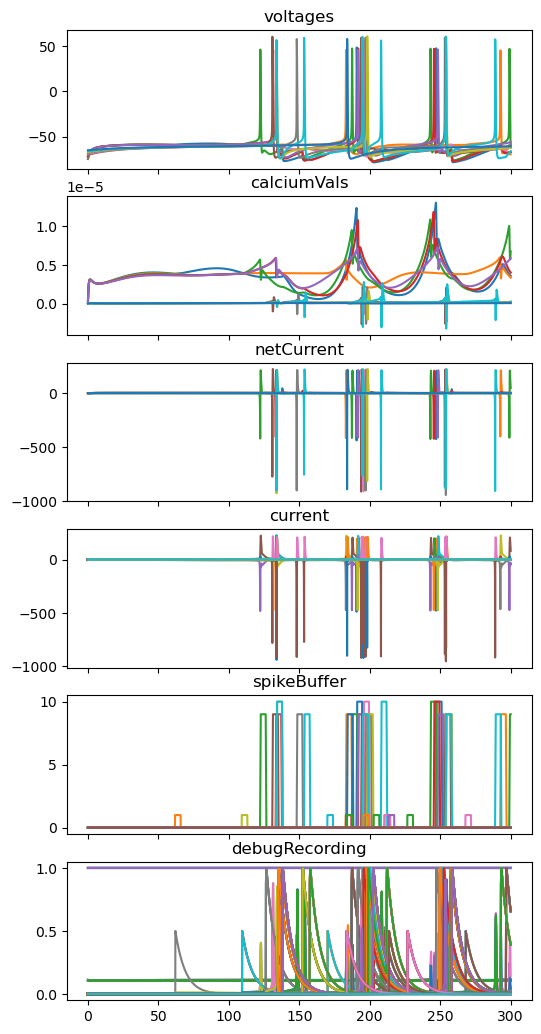

In [14]:
#theres different levels to this, each needs tools for simulating and testing
#channels
#spikers
#single compartment neurons
#multicompartment neurons
#neural populations 
#neural networks

#stimulate all ampa synapses on neuron 0?
#over write the spike output of neuron 1? 
#what you really need to be able to do is inject current into a specific neuron at a specific time point 
#which might mean that for the period of simulation you state exactly what the current value will be at each time point for every neuron 
#very memory inefficient, but might be fast on a gpu
#in python we specify the stimulation with indices and values for when the bias is anything other than the default value 
# bias overwrite as a parameter?

#new keys: spikerPreNeuron, spikerNeuronScale, nSpikers, channelPreSpiker (used to be preNeuron)

def solveNeurons(ac,biasOverWriteList,TS):
    #this function deals with determination of membrane voltage and calcium dynamics, 
    # i have moved spiking dynamics to the solveSpikers function 
    voltage = ac["voltages"]
    nNeurons = ac["nNeurons"]
    calciumVals = ac["calciumVals"]
    alpha = 1/(2*96485) #this is the conversion factor between current and Ca diffusion (1/zF). scale it up if you want Ca in different units 
    CaEquilibriumVal = ac["CaEquilibriumVal"] #1 I think 1e-6 is reasonble, otsuka is 0 
    CaRemovalRate = ac["CaRemovalRate"] #ms, this is the value otsuka uses, not sure where they get it from 
    for i in range(nNeurons):
        voltage[i] -= TS*(ac["netCurrent"][i]+ac["biasCurrents"][i]+biasOverWriteList[i])
        calciumVals[i] += TS*(-alpha*ac["netCaCurrent"][i] + (-calciumVals[i]+ CaEquilibriumVal[i])*CaRemovalRate[i]) #This requires some explaination:
                        #We need to convert Ca current (in uA/cm^2) to Ca concentration (in mol/L) so I hardcode the conversion factor 
                        #Cellular Ca is tightly regulated to ~uM concentrations, so I've included a fixed point at 1e-6.
                        #I've set the timeconstant for Ca regulation to be 0.5ms, which might be a little fast
                        #With this implementation its possible to have 1. calcium efflux (which is fine), and 2. negative Ca concentrations (which is not fine)
                        #but negative Ca would require persistent Vm>140mV which is unphysiological anyway. 



#TODO: neurons have a spike buffer but spikers should also have a very small buffer
#TODO: spikers shouldnt be allowed a full buffer, too expensive
#TODO: neurons shouldnt be allowed have a buffer because some of them might not be axons
#NOTE: Solution. spikers get to have buffers and we will measure the performance impact to see if its significant
        
def solveSpikers(ac):
    writeIndex = ac["writeIndex"]
    spikerPreNeuron = ac["spikerPreNeuron"] #this is the neuron that gets checked 
    spikerNeuronScale = ac["spikerNeuronScale"] #0 or 1
    voltages = ac["voltages"]
    spikeBuffer = ac["spikeBuffer"]
    nSpikers = ac["nSpikers"]
    spikerProbability = ac["spikerProbability"]
    for i in range(nSpikers):
        randomOutput = bool(np.random.random()<spikerProbability[i])
        spikeOutput =  bool(spikerNeuronScale[i]*int(voltages[spikerPreNeuron[i]]>0))  # here we could actually implement transmitter release and short term plasticity dynamics 
        spikeOutput = float(randomOutput or spikeOutput)                      # for now its very simple spike threshold 
        spikeBuffer[i][writeIndex[i]] = spikeOutput         
        writeIndex[i] = (writeIndex[i]+1)%ac["maxDelayInt"]


def solveChannels(ac,spikeOverwriteList,TS):
    nChannels = ac["nChannels"]
    voltage = ac["voltages"]
    calciumVals = ac["calciumVals"]
    writeIndex = ac["writeIndex"]
    maxDelay = ac["maxDelayInt"]
    for i in range(nChannels):
        postSynapticNeuron = ac["postNeuron"][i]
        V = voltage[postSynapticNeuron]
        Ca = calciumVals[postSynapticNeuron]
        preSynapticSpiker = ac["channelPreSpiker"][i] #for channel this is = to postSynaptic neuron, and does not matter
        #spikes = max(spikeVals[preSynapticSpiker],spikeOverwriteList[i])
        xs = ac["x"][i]
        xhs,xks = ac["vHalf"][i],ac["vKi"][i]
        xts0,xts1 = ac["tau0"][i],ac["tau1"][i]
        xths,xtks = ac["th"][i],ac["tkInv"][i]
        
        exponents = ac["exponent"][i]
        minOpenness = ac["minOpenness"][i]
        Erev = ac["Erev"][i]
        g0 = ac["conductance"][i]
        p = ac["efficacy"][i]
        w = ac["conductanceGain"][i]
        CaCurrent = ac["CaCurrent"][i]

        tempTS = TS
        gatingTotal = 1

        for j in range(len(xs)):
            x = xs[j]
            n = exponents[j]
            gatingTotal *= (x**n)

        g = g0 + w*p
        I = g*gatingTotal*(V-Erev) 
        ac["netCurrent"][postSynapticNeuron] += I
        ac["netCaCurrent"][postSynapticNeuron] += CaCurrent*I
        ac["current"][i] = I
        ac["debugRecording"][i] = gatingTotal

        synapseDelay = ac["inputDelay"][i]
        readIndex = int((writeIndex[preSynapticSpiker]-synapseDelay)%maxDelay)
        perceivedSpike = ac["spikeBuffer"][preSynapticSpiker][readIndex]
        perceivedSpike = max(perceivedSpike,spikeOverwriteList[i])

        xs[0] = solveGate(xs[0],V,tempTS,xhs[0],xks[0],xts0[0],xts1[0],xths[0],xtks[0],minOpenness[0]) #gate1
        xs[1] = solveGate(xs[1],V,tempTS,xhs[1],xks[1],xts0[1],xts1[1],xths[1],xtks[1],minOpenness[1]) #gate2
        xs[2] = solveGate(xs[2],Ca,tempTS,xhs[2],xks[2],xts0[2],xts1[2],xths[2],xtks[2],minOpenness[2]) #CaGate
        xs[3] = solveGate(xs[3],perceivedSpike,tempTS,xhs[3],xks[3],xts0[3],xts1[3],xths[3],xtks[3],minOpenness[3]) #spikeGate

        dp = calcWeightChange(p,Ca,ac["rate"][i],ac["gammaP"][i],ac["gammaD"][i],ac["thetaP"][i],ac["thetaD"][i])
        ac["efficacy"][i]+=TS*dp


def solveSystemStandard(ac,TS,runTime,stimInfoSpikes={},stimInfoCurrents= {},
                        recordingKeys = ["voltages","calciumVals","netCurrent","current","spikeBuffer"]):
    nIterations = int(runTime/TS)
    data = {key:[] for key in recordingKeys}
    tv = np.linspace(0,runTime,nIterations)
    nNeurons = ac["nNeurons"]
    nChannels = ac["nChannels"]
    for iteration,t in enumerate(tv):
        #calculate currents
        ac["netCurrent"] = np.zeros([nNeurons])
        ac["netCaCurrent"] = np.zeros([nNeurons])
        spikeOverwriteList = np.zeros(nChannels)
        biasOverWriteList = np.zeros(nNeurons)
        if iteration in stimInfoSpikes.keys():
            for syn in stimInfoSpikes[iteration]:
                spikeOverwriteList[syn] = 1
                
        if iteration in stimInfoCurrents.keys():
            for neur,val in stimInfoCurrents[iteration].items():
                biasOverWriteList[neur] = val

        #update the gates
        solveChannels(ac,spikeOverwriteList,TS)

        solveDiffusiveConnections(ac)

        solveNeurons(ac,biasOverWriteList,TS)

        solveSpikers(ac)

        for key in data:
            data[key].append(deepcopy(ac[key]))

    for key in data:
        data[key] = np.array(data[key])
    data["time"] = tv
    return data


#TODO: synapses to stim doesnt work, need to figure out why
synapsesToStim = [] #[connectionToChannelMap["STNtoGPe"][1]]
runTime = 300
biasNeuron,biasVal = 0,-10
st0,st1=10,11
st0,st1 = int(st0/TS),int(st1/TS)
stimInfoCurrents = {} #{i:{biasNeuron:biasVal} for i in range(st0,st1)}
# channel inputs are overwritten at a particular iteration, on a per channel basis (as opposed to overwritting a axon)
stimInfoSpikes = {} #{i:synapsesToStim for i in range(st0,st1)}
simDataPy = deepcopy(simData)
simDataPy["debugRecording"] = np.zeros_like(simDataPy["current"])
data = solveSystemStandard(simDataPy,TS,runTime,stimInfoSpikes,stimInfoCurrents,recordingKeys = ["voltages","calciumVals","netCurrent","current","spikeBuffer","debugRecording"])
standardPlot(data)
#plt.plot(data["time"],data["debugRecording"][:,synapsesToStim])

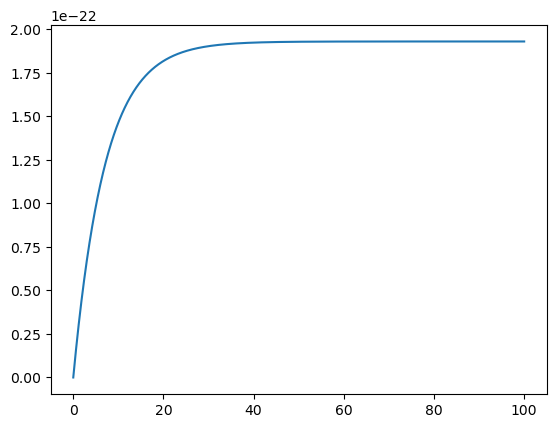

In [60]:
plt.plot(data["time"],data["debugRecording"][:,140])

In [45]:
connectionToChannelMap["CTXtoSTN"][1]

126

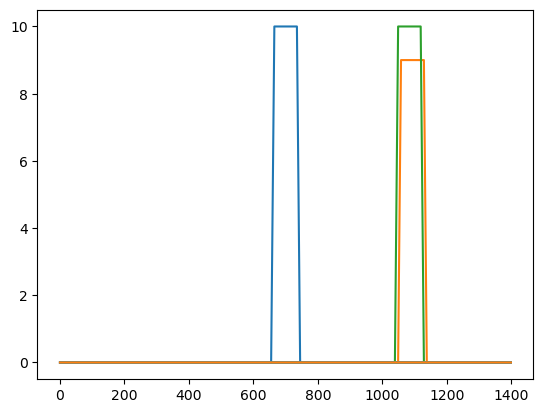

In [4]:
x = data["spikeBuffer"].sum(axis=2)
plt.plot(x);

[[False False  True ... False False False]
 [False False  True ... False False False]
 [False False  True ... False False False]
 ...
 [False False False ... False False False]
 [False False False ... False False False]
 [False False False ... False False False]]


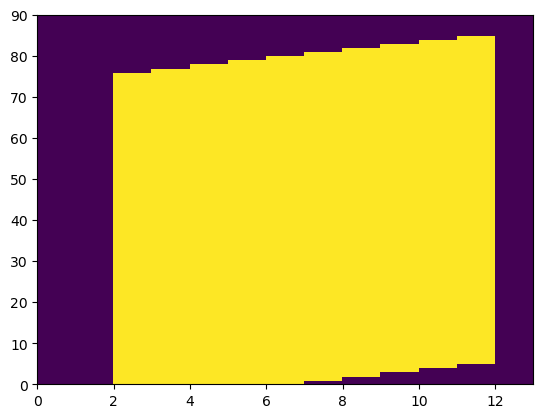

In [5]:
y = data["spikeBuffer"][660:750,0,14:27]
plt.pcolor(y)
print(y)